# Where the canopy runs out

The City of Melbourne records each of its 82,064 trees with a species, a planting year and a useful life expectancy:
the years it has left as a healthy, safe tree, in bands (under 10 years, 11 to 20, 21 to 30, 31 to 40, over 41). The
council also maps its tree canopy from aerial imagery, as outlines. Neither says which streets and blocks lose their
shade, and when.

Three things were added in [Plotlay](https://www.getplotlay.com):

1. each tree's share of the 2021 canopy outline its trunk stands in (prepared in Python, `data/trees/trees.csv`);
2. the 603 census blocks and the 1,809 road segments that hold a council tree, taken from the council's files and keyed
   by `block_id` and `seg_id`, with the trees placed in them by position;
3. formula columns for the shade now and in each decade, and the 13 precincts rolling the blocks up.

This notebook reads only the files in `../data` and recomputes every number on the page, top to bottom.

In [1]:
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

DATA = '../data'
pd.set_option('display.width', 140)
INK, RED, MUTED = '#1d4f91', '#cf3b26', '#5b6573'
YEARS = [2025, 2035, 2045, 2055, 2065]
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

## Sources and licence

Trees (with species and dimensions), tree canopies 2021, CLUE blocks, CLUE small areas and road corridors: City of
Melbourne Open Data, under CC BY 4.0. The full credits are in `NOTICE`. Nothing here comes from OpenStreetMap, and no
imagery was traced.

## The trees

`trees.csv` has one row per council tree: its useful life band, the year its useful life ends by (`end_by`, the top of
the band counted from 2025, the dataset's last update), and `canopy_m2`, its share of the 2021 canopy.

A tree's share is the part of the canopy outline its trunk stands in (or the nearest outline within 3 m) that is nearer
to it than to any other council tree in that outline, and within 15 m of its trunk. Only Mature and Semi-mature trees
claim canopy: a newly planted tree gives no measured shade yet. Trees with no band (17,410; the portal's value column
says 50 for them, which is a fill) are "Not assessed": they are counted as standing.

In [2]:
trees = pd.read_csv(f'{DATA}/trees/trees.csv', dtype={'com_id': str})
print(f'{len(trees):,} trees; {(trees.canopy_m2 > 0).sum():,} with canopy; {trees.canopy_m2.sum() / 1e4:,.1f} ha of shade')
trees.ule_band.value_counts()

82,064 trees; 59,440 with canopy; 274.0 ha of shade


ule_band
> 41 years       22604
21 - 30 years    21115
Not assessed     17410
31 - 40 years    15989
11 - 20 years     4283
< 10 years         663
Name: count, dtype: int64

## The shade standing at each decade

Each tree is taken as gone by the top of its band: a tree with "11 - 20 years" left is gone by 2045 at the latest. It
could go sooner, so these are the latest dates, and if the council assessed a tree before 2025 its date comes sooner
still. New plantings are not counted: this is the shade today's trees give.

In [3]:
total = trees.canopy_m2.sum()
standing = {y: trees[trees.end_by.isna() | (trees.end_by > y)].canopy_m2.sum() for y in YEARS}
table = pd.DataFrame({'standing_ha': {y: v / 1e4 for y, v in standing.items()}})
table['lost_ha'] = (total - pd.Series(standing)) / 1e4
table['lost_pct'] = 100 * (total - pd.Series(standing)) / total
table['trees_ending'] = [int((trees.end_by <= y).sum()) for y in YEARS]
table.round(1)

,standing_ha,lost_ha,lost_pct,trees_ending
2025,274.0,0.0,0.0,0
2035,272.6,1.4,0.5,663
2045,252.2,21.8,8.0,4946
2055,116.8,157.2,57.4,26061
2065,58.6,215.5,78.6,42050


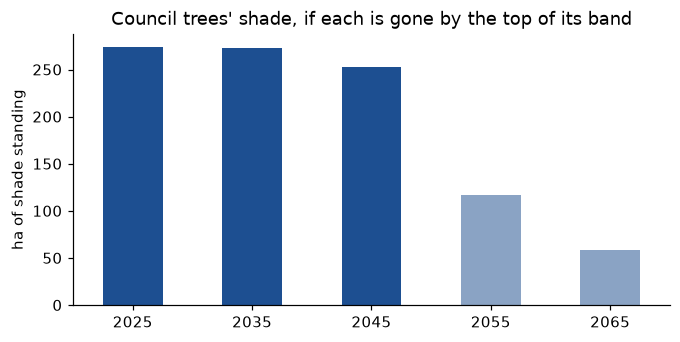

In [4]:
ax = table.standing_ha.plot.bar(color=[INK, INK, INK, '#8aa3c4', '#8aa3c4'], figsize=(7, 3.2), rot=0)
ax.set_ylabel('ha of shade standing'); ax.set_title("Council trees' shade, if each is gone by the top of its band")
plt.show()

## Which species carry the shade that ends by 2045

In [5]:
soon = trees[trees.end_by <= 2045]
sp = soon.groupby('common_name').agg(ha=('canopy_m2', lambda s: s.sum() / 1e4), trees=('com_id', 'count')).sort_values('ha', ascending=False)
elm = soon[soon.genus == 'Ulmus'].canopy_m2.sum()
print(f'Elms of every kind: {elm / 1e4:.1f} ha, {100 * elm / soon.canopy_m2.sum():.0f}% of the shade ending by 2045')
sp.head(10).round(2)

Elms of every kind: 8.0 ha, 37% of the shade ending by 2045


,ha,trees
common_name,,
English Elm,5.28,435
London Plane,2.29,252
River red gum,1.47,698
Dutch Elm,0.88,97
Huntingdon Elm,0.65,74
Sugar gum,0.56,44
Moreton Bay Fig,0.56,37
Spotted Gum,0.49,106
Smooth-Leaved Elm,0.46,38


## The blocks, as keyed and worked out in Plotlay

`blocks.geojson` is Plotlay's export of the Blocks layer: each block keyed by its `block_id`, with the formula columns
`canopy_2025` to `canopy_2065` (`coalesce(sum(canopy_m2, year = 2045), 0)` over the trees placed in it),
`lost_by_2045` and `pct_lost_by_2045`. Below, the same numbers are worked out again from the trees, placed in the
blocks by GeoPandas, and compared.

In [6]:
blocks = gpd.read_file(f'{DATA}/geometry/blocks.geojson')
for c in ['canopy_2025', 'canopy_2045', 'lost_by_2045', 'pct_lost_by_2045']: blocks[c] = pd.to_numeric(blocks[c])
g = gpd.GeoDataFrame(trees, geometry=gpd.points_from_xy(trees.lng, trees.lat), crs=4326)
j = gpd.sjoin(g, blocks[['key', 'geometry']], predicate='within')
j['lost'] = j.canopy_m2.where(j.end_by <= 2045, 0)
again = j.groupby('key').agg(canopy=('canopy_m2', 'sum'), lost=('lost', 'sum'))
cmp = blocks.set_index('key')[['canopy_2025', 'lost_by_2045']].join(again).fillna(0)
print('largest difference, Plotlay against GeoPandas:', round(float((cmp.canopy_2025 - cmp.canopy).abs().max()), 1), 'm² of shade,',
      round(float((cmp.lost_by_2045 - cmp.lost).abs().max()), 1), 'm² lost')

largest difference, Plotlay against GeoPandas: 153.3 m² of shade, 0.5 m² lost


In [7]:
print('Blocks losing the most shade by 2045 (m²)')
blocks.sort_values('lost_by_2045', ascending=False)[['key', 'area_name', 'canopy_2025', 'lost_by_2045', 'pct_lost_by_2045']].head(10)

Blocks losing the most shade by 2045 (m²)


,key,area_name,canopy_2025,lost_by_2045,pct_lost_by_2045
570,931,Parkville,437455.3,30871,7.1
139,852,Melbourne (Remainder),232371.0,18659,8.0
583,866,South Yarra,129440.2,17459,13.5
481,619,East Melbourne,127232.9,14391,11.3
3,274,Carlton,102944.4,9611,9.3
4,269,Carlton,44417.3,7690,17.3
235,273,Carlton,14040.8,5746,40.9
70,653,East Melbourne,29767.3,5234,17.6
377,271,Parkville,14512.1,2436,16.8
95,554,Kensington,20398.0,2269,11.1


In [8]:
big = blocks[blocks.canopy_2025 >= 2000]
print(f'{len(big)} blocks have 2,000 m² of council-tree shade or more; {(big.pct_lost_by_2045 >= 25).sum()} lose a quarter of it or more by 2045')
big.sort_values('pct_lost_by_2045', ascending=False)[['key', 'area_name', 'canopy_2025', 'lost_by_2045', 'pct_lost_by_2045']].head(10)

262 blocks have 2,000 m² of council-tree shade or more; 9 lose a quarter of it or more by 2045


,key,area_name,canopy_2025,lost_by_2045,pct_lost_by_2045
68,605,East Melbourne,2946.1,1382,46.9
235,273,Carlton,14040.8,5746,40.9
428,219,Carlton,2265.9,908,40.1
527,660,Melbourne (Remainder),6090.2,2236,36.7
275,131,Docklands,2541.3,933,36.7
225,266,Carlton,2560.3,779,30.4
73,616,East Melbourne,2915.4,754,25.9
463,1112,Docklands,2511.2,644,25.6
471,649,East Melbourne,6912.8,1759,25.4
370,907,Parkville,2188.2,493,22.5


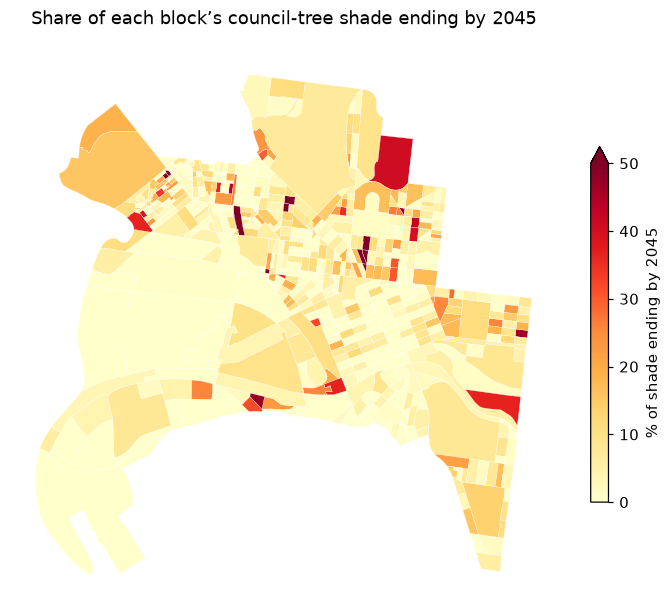

In [9]:
ax = blocks.to_crs(7855).plot(column='pct_lost_by_2045', cmap='YlOrRd', vmin=0, vmax=50, figsize=(8, 7), legend=True,
    legend_kwds={'label': '% of shade ending by 2045', 'shrink': .6}, edgecolor='white', linewidth=.2,
    missing_kwds={'color': '#eee'})
ax.set_axis_off(); ax.set_title('Share of each block’s council-tree shade ending by 2045')
plt.show()

## The streets

`streets.geojson` is the Streets layer: each road corridor segment that holds a council tree, keyed by `seg_id`, with
the same columns. Segments are added up into streets by the name at the start of the council's description.

In [10]:
streets = gpd.read_file(f'{DATA}/geometry/streets.geojson')
for c in ['canopy_2025', 'lost_by_2045']: streets[c] = pd.to_numeric(streets[c])
streets['street'] = streets.seg_descr.str.replace(r'^Intersection of ', '', regex=True).str.split(r' between | from | and |,').str[0].str.strip()
by = streets.groupby('street').agg(canopy=('canopy_2025', 'sum'), lost_m2=('lost_by_2045', 'sum'), segments=('key', 'count'))
by['pct'] = 100 * by.lost_m2 / by.canopy
by.sort_values('lost_m2', ascending=False).head(12).round(1)

,canopy,lost_m2,segments,pct
street,,,,
St Kilda Road,50809.8,5259,23,10.4
Swanston Street,21638.8,2385,25,11.0
Punt Road,9254.1,2170,20,23.4
Dryburgh Street,7333.1,1967,16,26.8
Rathdowne Street,10076.4,1876,15,18.6
Simpson Street,4608.2,1606,10,34.9
George Street,6370.4,1580,4,24.8
Cardigan Street,9904.8,1537,14,15.5
Upfield Railway,6281.6,1313,2,20.9


## The precincts, rolled up in Plotlay

`precincts.geojson`: the 13 census small areas, with roll-up columns (`sum(canopy_2025) of Blocks inside`; a block
belongs to the precinct holding its centre).

In [11]:
prec = gpd.read_file(f'{DATA}/geometry/precincts.geojson')
for c in ['canopy_2025', 'lost_by_2045', 'pct_lost_by_2045', 'blocks']: prec[c] = pd.to_numeric(prec[c])
print('blocks rolled up:', int(prec.blocks.sum()))
prec.sort_values('pct_lost_by_2045', ascending=False)[['key', 'canopy_2025', 'lost_by_2045', 'pct_lost_by_2045', 'blocks']]

blocks rolled up: 602


,key,canopy_2025,lost_by_2045,pct_lost_by_2045,blocks
10,East Melbourne,296258.6,34266,11.6,37
7,Carlton,332017.3,38115,11.5,71
0,South Yarra,177936.7,19750,11.1,17
6,Docklands,79516.8,6940,8.7,17
11,Kensington,214731.9,17530,8.2,117
2,Melbourne (Remainder),390372.5,28660,7.3,15
3,North Melbourne,215217.1,15237,7.1,94
8,Parkville,588415.8,41998,7.1,34
5,Port Melbourne,42048.3,2095,5.0,18
12,West Melbourne (Residential),84738.0,3842,4.5,48


## Read it carefully

- The bands are the council's assessments. The dataset does not say when each tree was assessed, so every date here is
  counted from 2025 and is the latest the band allows.
- Canopy is the 2021 outline. Trees planted since have no measured shade, and a tree's crown may have grown or shrunk.
- A Voronoi split gives a small tree beside a big one an equal claim on the outline between them. Totals for a block or
  a street are steadier than any one tree's figure.
- Canopy in outlines holding no council tree (private gardens, trees the council does not manage) is left out.